# Figure 6: Change-point summary

Asks whether participants adjust their decision bound around a **change point (CP)**, where the
SNR switches mid-trial (block 3: low → high SNR; block 4: high → low), in two ways:

- **Anticipation** — a tilt of the bound over the steps *before* the CP. The CP time is fixed per
  subject and block, so a subject who has learned it could tilt the bound toward it.
- **Step** — a jump of the bound *at* the CP.

Participants collapse their bounds within a trial whether or not a change is coming, so each
measure is taken in the CP block **and in its matched fixed block** (same starting SNR: block 1
for low → high, block 2 for high → low), over the same window, and compared per subject. The
fixed block has no change point; it gets the subject's CP time from the matched block as a
pseudo change point, so the window and the step time are identical.

**Figure** — 4 rows × 2 columns (low → high, high → low):

- **A, B** — reward-rate incentive for a pre-CP bound slope (change-specific: the same slope's
  effect without the SNR change is subtracted). Red line + band: median and IQR over subjects'
  own fitted models (no single optimum is marked; the median curve's optimum and gain are printed
  below, for the caption). Black line:
  median change − fixed slope (panels C, D).
- **C, D** — pre-CP bound slope, CP block (y) vs. fixed block (x). Δ = median change − fixed
  (log units per step), Wilcoxon signed-rank p.
- **E, F** — reward-rate incentive for a step at the CP (post / pre plateau ratio). Black line:
  median change / fixed step (panels G, H).
- **G, H** — post / pre bound at the (pseudo) CP, CP block vs. fixed block, log axes.
  Δ = median log(CP step) − log(fixed step).

Scatters: dotted line = identity; large black dot = median subject; gray crosses = a slope or
plateau at a fit limit (excluded from statistics, counted below); points beyond the axes are drawn
on the edge.

## Pipeline (run from the project root before this notebook)

1. `scripts/run_stopping_fits_cp.py cp_plateau_pair` — stage 1: per-subject fit of all four
   blocks: knee-form bound time course per block pair (blocks 1 + 3, 2 + 4), per-block plateau,
   CV, guess / lapse / anticipation rates, post-CP plateau in blocks 3 and 4 (~3 h).
2. `scripts/run_stopping_fits_cp_matched.py cp_matched` — stage 2: everything from stage 1 fixed
   except, in every block, the pre-CP plateau, the post-CP plateau and a pre-CP slope; fixed
   blocks use the pseudo CP (~1 min).
3. `scripts/run_cp_incentive_sims.py` — reward-rate incentives from each subject's stage-1
   model (a few minutes).


In [1]:
import sys
sys.path.insert(0, '..')


import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import CM, FS_INSET, DATA_COLOR, OPTIMAL_COLOR, add_panel_label, format_p, use_figure_style
from pigeon.stopping import get_plateau_at_limit, get_stopping_model_trials

## Load data

- `fits`: stage-2 matched-block fit (`stopping_fits_cp_matched.pkl`), one row per subject × block.
  `slope_pre` is the pre-CP slope of log bound per step; `bound_scale` is the pre-CP bound at the
  (pseudo) CP and `bound_scale_post` the post-CP plateau, so their ratio is the step.
- `step_sims`, `slope_sims`: reward rates from `run_cp_incentive_sims.py`.
- Trials (for CP times and exclusion counts) come from `get_stopping_model_trials`, which prints
  its exclusions; only subjects with all four blocks are fit.

**Fit limits.** Slopes are bounded to ±0.15 per step and plateaus to [0.002, 2]. A subject whose
slope (CP or fixed block) sits at the limit is left out of the slope statistics; one whose pre- or
post-CP plateau (either block) sits at a limit is left out of the step statistics. Counts are
printed, and these subjects are drawn as gray crosses.

In [2]:
PROCESSED = DATA_DIR
CONDITIONS = {'LowHigh': ('B3', 'B1'), 'HighLow': ('B4', 'B2')}   # condition: (CP block, matched fixed block)
SLOPE_LIMIT = 0.15                                                   # pigeon.stopping late-slope limit

trials = get_stopping_model_trials('MXSC', [1, 2, 3, 4])
fits = pd.read_pickle(PROCESSED / 'stopping_fits_cp_matched.pkl')
fits = fits.assign(
    step=fits.bound_scale_post / fits.bound_scale,
    plateau_limit=get_plateau_at_limit(fits) | get_plateau_at_limit(fits.assign(bound_scale=fits.bound_scale_post)))
step_sims = pd.read_pickle(PROCESSED / 'cp_incentive_step.pkl')
slope_sims = pd.read_pickle(PROCESSED / 'cp_incentive_slope.pkl')

wide = lambda col: fits.pivot(index='subject_index', columns='group', values=col)  # noqa: E731
slopes, steps, plateau_limit = wide('slope_pre'), wide('step'), wide('plateau_limit').astype(bool)
print(f"{fits.subject_index.nunique()} subjects fit; converged: {fits.groupby('subject_index').success.first().sum()}")
cp_times = trials[trials.block_index > 2].groupby(['block_index', 'subject_index']).change_point.first()
for (cond, (cp_block, _)), blk in zip(CONDITIONS.items(), (3, 4)):
    c = cp_times.loc[blk]
    print(f"{cond}: CP step median {c.median():.0f} [IQR {c.quantile(.25):.0f}, {c.quantile(.75):.0f}], "
          f"range {c.min():.0f}-{c.max():.0f}")

MXSC: subjects with a good adaptation tau fit, by block: {1: 10, 2: 23, 3: 26, 4: 17}
MXSC: 30,214 trials in blocks [1, 2, 3, 4]; excluded 2,214 with trial_number < 10, 349 more in the adaptation transient, 236 more with no choice; 65 subjects
60 subjects fit; converged: 60
LowHigh: CP step median 12 [IQR 7, 16], range 3-25
HighLow: CP step median 7 [IQR 5, 9], range 3-20


## Statistics

Per condition:

- **Slope (C, D)**: per-subject difference `slope_pre(CP block) − slope_pre(fixed block)`; median,
  IQR, count > 0 and two-sided Wilcoxon signed-rank p (H0: median difference 0).
- **Step (G, H)**: per-subject `log(step CP) − log(step fixed)`; same summaries. Each block's step
  is also tested against 1 on its own.
- **Incentives (A, B, E, F)**: per-subject reward-rate change in % of the reward rate without the
  manipulation. Slope: change-specific, `(RR_cp(s) − RR_cp(0)) − (RR_base(s) − RR_base(0))`. Step:
  relative to a ratio of 1, lightly smoothed (3-point running mean over the ratio grid) against
  simulation noise. The optimum is that of the median curve.

In [3]:
def summarize(d):
    q1, q3 = d.quantile([0.25, 0.75])
    return dict(n=len(d), median=d.median(), q1=q1, q3=q3, n_pos=int((d > 0).sum()),
                p=scipy.stats.wilcoxon(d).pvalue)


# Slope and step differences
stats = {}
for cond, (cpb, fb) in CONDITIONS.items():
    l_slope = (slopes[[cpb, fb]].abs() > SLOPE_LIMIT - 1e-3).any(axis=1)
    l_step = plateau_limit[cpb] | plateau_limit[fb]
    d_slope = (slopes[cpb] - slopes[fb])[~l_slope]
    d_step = (np.log(steps[cpb]) - np.log(steps[fb]))[~l_step]
    stats[cond] = dict(l_slope=l_slope, l_step=l_step, slope=summarize(d_slope), step=summarize(d_step),
                       step_cp=summarize(np.log(steps[cpb][~l_step])), step_fixed=summarize(np.log(steps[fb][~l_step])))
    s, t = stats[cond]['slope'], stats[cond]['step']
    print(f"{cond}:")
    print(f"  slope, change - fixed: median {s['median']:+.4f} [IQR {s['q1']:+.4f}, {s['q3']:+.4f}], "
          f"{s['n_pos']}/{s['n']} > 0, {format_p(s['p'])}  ({l_slope.sum()} at the slope limit)")
    print(f"     CP block median {slopes[cpb][~l_slope].median():+.4f}, fixed block {slopes[fb][~l_slope].median():+.4f}")
    print(f"  step, log change - log fixed: median {t['median']:+.3f} [IQR {t['q1']:+.3f}, {t['q3']:+.3f}] "
          f"(ratio {np.exp(t['median']):.2f}), {t['n'] - t['n_pos']}/{t['n']} < 0, {format_p(t['p'])}  "
          f"({l_step.sum()} at a plateau limit)")
    for which in ('step_cp', 'step_fixed'):
        u = stats[cond][which]
        print(f"     {which.replace('step_', '')} block step median {np.exp(u['median']):.3f}, vs 1: {format_p(u['p'])}")

# Incentive curves (rows: subjects, columns: slope or ratio), % reward-rate change
slope_gain, step_gain = {}, {}
for cond in CONDITIONS:
    g = slope_sims[slope_sims.condition == cond].pivot_table(index=['subject_index', 'slope'], columns='kind',
                                                              values='rr')
    g0 = g.xs(0.0, level='slope')
    g = g.join(g0, on='subject_index', rsuffix='0')
    slope_gain[cond] = (100 * ((g.cp - g.cp0) - (g.base - g.base0)) / g.cp0).unstack('slope')
    m = step_sims[step_sims.condition == cond].pivot(index='subject_index', columns='ratio', values='rr')
    x = np.log(m.columns.to_numpy())
    r0 = m.apply(lambda row: np.interp(0, x, row.to_numpy()), axis=1)
    v = (100 * m.sub(r0, axis=0).div(r0.abs(), axis=0)).to_numpy().copy()
    v[:, 1:-1] = (v[:, :-2] + v[:, 1:-1] + v[:, 2:]) / 3
    step_gain[cond] = pd.DataFrame(v, index=m.index, columns=m.columns)
    for name, G in (('slope', slope_gain[cond]), ('step', step_gain[cond])):
        med = G.median()
        i = int(np.argmax(med.to_numpy()))
        edge = '' if 0 < i < len(med) - 1 else ' (grid edge)'
        print(f"{cond} {name} incentive: median-curve optimum at {med.index[i]:.3g}{edge}, gain {med.iloc[i]:+.2f}% "
              f"(n={len(G)})")

LowHigh:
  slope, change - fixed: median +0.0131 [IQR -0.0079, +0.0364], 34/53 > 0, p=0.015  (7 at the slope limit)
     CP block median -0.0079, fixed block -0.0174
  step, log change - log fixed: median -0.223 [IQR -0.430, -0.016] (ratio 0.80), 44/57 < 0, p<0.001  (3 at a plateau limit)
     cp block step median 0.878, vs 1: p=0.001
     fixed block step median 1.064, vs 1: p=0.008
HighLow:
  slope, change - fixed: median -0.0048 [IQR -0.0450, +0.0304], 26/56 > 0, p=0.574  (4 at the slope limit)
     CP block median -0.0123, fixed block -0.0062
  step, log change - log fixed: median +0.030 [IQR -0.200, +0.240] (ratio 1.03), 27/59 < 0, p=0.478  (1 at a plateau limit)
     cp block step median 1.040, vs 1: p=0.202
     fixed block step median 1.015, vs 1: p=0.740
LowHigh slope incentive: median-curve optimum at 0.15, gain +2.02% (n=60)
LowHigh step incentive: median-curve optimum at 1.12, gain -0.02% (n=60)
HighLow slope incentive: median-curve optimum at -0.6 (grid edge), gain +2.80% 

## Figure

17.6 cm wide (two-column), 12-pt labels, 8-pt in-panel statistics. Anticipation on top (A–D),
step below (E–H). Saves `Figure06.pdf` and `.png` to `FIGURES_DIR`.

LowHigh: drawn on the axis edge: 0 (slopes), 3 (steps)
HighLow: drawn on the axis edge: 0 (slopes), 2 (steps)


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


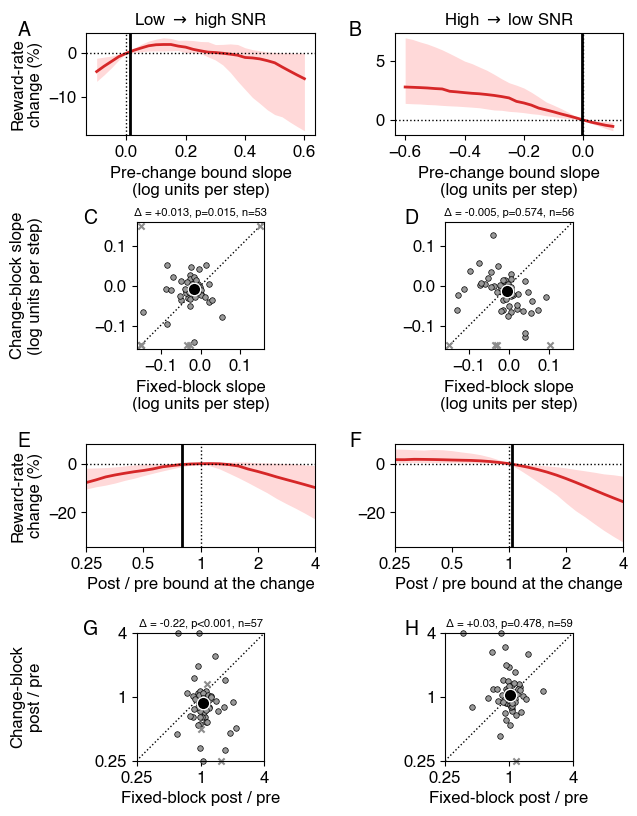

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure06.pdf (+ .png)


In [4]:
RATIO_LIM = (0.25, 4)
BAND = (1.0, 0.85, 0.85)
TITLES = {'LowHigh': r'Low $\rightarrow$ high SNR', 'HighLow': r'High $\rightarrow$ low SNR'}
use_figure_style()


def plot_incentive(ax, G):
    x = G.columns.to_numpy()
    ax.fill_between(x, G.quantile(0.25), G.quantile(0.75), color=BAND, lw=0, zorder=0)
    ax.plot(x, G.median(), color=OPTIMAL_COLOR, lw=2)
    ax.axhline(0, color='k', ls=':', lw=1)


def plot_matched(ax, x, y, l_ex, lo, hi, log_scale=False):
    ax.plot([lo, hi], [lo, hi], color='k', ls=':', lw=1, zorder=1)
    xc, yc = np.clip(x, lo, hi), np.clip(y, lo, hi)   # beyond-axis points sit on the edge
    ax.scatter(xc[~l_ex], yc[~l_ex], s=16, facecolor='0.6', edgecolor='k', lw=0.5, zorder=2, clip_on=False)
    ax.scatter(xc[l_ex], yc[l_ex], marker='x', color='0.55', s=20, zorder=2, clip_on=False)
    center = (lambda v: np.exp(np.log(v).median())) if log_scale else (lambda v: v.median())
    ax.plot(center(x[~l_ex]), center(y[~l_ex]), 'o', color=DATA_COLOR, markersize=9, markeredgecolor='w', zorder=3)
    if log_scale:
        ax.set_xscale('log')
        ax.set_yscale('log')
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal')
    return int(((x[~l_ex] != xc[~l_ex]) | (y[~l_ex] != yc[~l_ex])).sum())


def ratio_axis(axis, ticks):
    axis.set_major_locator(mt.FixedLocator(ticks))
    axis.set_major_formatter(mt.FixedFormatter([str(t) for t in ticks]))
    axis.set_minor_locator(mt.NullLocator())


fig = plt.figure(figsize=(17.6 * CM, 24 * CM))
outer = fig.add_gridspec(2, 1, hspace=0.3)
grids = [outer[k].subgridspec(2, 2, hspace=0.75, wspace=0.35, height_ratios=[1, 1.25]) for k in range(2)]
axs = np.array([[fig.add_subplot(g[i, j]) for j in range(2)] for g in grids for i in range(2)])
lim = SLOPE_LIMIT + 0.01
for ci, (cond, (cpb, fb)) in enumerate(CONDITIONS.items()):
    st = stats[cond]
    dx = -0.3 if ci == 0 else -0.2
    # A, B
    ax = axs[0, ci]
    plot_incentive(ax, slope_gain[cond])
    ax.axvline(0, color='k', ls=':', lw=1)
    ax.axvline(st['slope']['median'], color=DATA_COLOR, lw=2, zorder=2)
    ax.set_xlabel('Pre-change bound slope\n(log units per step)')
    ax.set_title(TITLES[cond])
    add_panel_label(ax, 'AB'[ci], dx=dx, dy=1.12)
    # C, D
    ax = axs[1, ci]
    n_edge = plot_matched(ax, slopes[fb], slopes[cpb], st['l_slope'], -lim, lim)
    ax.text(0.5, 1.03, f"Δ = {st['slope']['median']:+.3f}, {format_p(st['slope']['p'])}, n={st['slope']['n']}",
            transform=ax.transAxes, ha='center', va='bottom', fontsize=FS_INSET)
    ax.xaxis.set_major_locator(mt.MultipleLocator(0.1))
    ax.yaxis.set_major_locator(mt.MultipleLocator(0.1))
    ax.set_xlabel('Fixed-block slope\n(log units per step)')
    add_panel_label(ax, 'CD'[ci], dx=dx - 0.12, dy=1.1)
    # E, F
    ax = axs[2, ci]
    G = step_gain[cond]
    plot_incentive(ax, G.loc[:, (G.columns >= RATIO_LIM[0] * 0.99) & (G.columns <= RATIO_LIM[1] * 1.01)])
    ax.axvline(1, color='k', ls=':', lw=1)
    ax.axvline(np.exp(st['step']['median']), color=DATA_COLOR, lw=2, zorder=2)
    ax.set_xscale('log')
    ax.set_xlim(RATIO_LIM)
    ratio_axis(ax.xaxis, [0.25, 0.5, 1, 2, 4])
    ax.set_xlabel('Post / pre bound at the change')
    add_panel_label(ax, 'EF'[ci], dx=dx, dy=1.12)
    # G, H
    ax = axs[3, ci]
    n_edge_step = plot_matched(ax, steps[fb], steps[cpb], st['l_step'], *RATIO_LIM, log_scale=True)
    ratio_axis(ax.xaxis, [0.25, 1, 4])
    ratio_axis(ax.yaxis, [0.25, 1, 4])
    ax.text(0.5, 1.03, f"Δ = {st['step']['median']:+.2f}, {format_p(st['step']['p'])}, n={st['step']['n']}",
            transform=ax.transAxes, ha='center', va='bottom', fontsize=FS_INSET)
    ax.set_xlabel('Fixed-block post / pre')
    add_panel_label(ax, 'GH'[ci], dx=dx - 0.12, dy=1.1)
    print(f"{cond}: drawn on the axis edge: {n_edge} (slopes), {n_edge_step} (steps)")
ylo = min(a.get_ylim()[0] for a in axs[2])
yhi = max(a.get_ylim()[1] for a in axs[2])
for a in axs[2]:
    a.set_ylim(ylo, yhi)
axs[0, 0].set_ylabel('Reward-rate\nchange (%)')
axs[1, 0].set_ylabel('Change-block slope\n(log units per step)')
axs[2, 0].set_ylabel('Reward-rate\nchange (%)')
axs[3, 0].set_ylabel('Change-block\npost / pre')
fig.align_ylabels(axs[:, 0])

out = FIGURES_DIR / 'Figure06.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Statistics table

Every statistic quoted in the figure, with the per-block steps and the exclusion counts.

In [5]:
rows = []
for cond, st in stats.items():
    s, t = st['slope'], st['step']
    rows.append({'Condition': cond, 'Measure': 'Slope, change − fixed (log units/step)', 'n': s['n'],
                 'Median [IQR]': f"{s['median']:+.4f} [{s['q1']:+.4f}, {s['q3']:+.4f}]",
                 'Subjects > 0': f"{s['n_pos']}/{s['n']}", 'p': format_p(s['p']),
                 'Excluded (fit limit)': int(st['l_slope'].sum())})
    rows.append({'Condition': cond, 'Measure': 'Step, log change − log fixed', 'n': t['n'],
                 'Median [IQR]': f"{t['median']:+.3f} [{t['q1']:+.3f}, {t['q3']:+.3f}]",
                 'Subjects > 0': f"{t['n_pos']}/{t['n']}", 'p': format_p(t['p']),
                 'Excluded (fit limit)': int(st['l_step'].sum())})
    for which, label in (('step_cp', 'Step, CP block (log)'), ('step_fixed', 'Step, fixed block (log)')):
        u = st[which]
        rows.append({'Condition': cond, 'Measure': label, 'n': u['n'],
                     'Median [IQR]': f"{u['median']:+.3f} [{u['q1']:+.3f}, {u['q3']:+.3f}]",
                     'Subjects > 0': f"{u['n_pos']}/{u['n']}", 'p': format_p(u['p']),
                     'Excluded (fit limit)': int(st['l_step'].sum())})
pd.DataFrame(rows)

,Condition,Measure,n,Median [IQR],Subjects > 0,p,Excluded (fit limit)
0,LowHigh,"Slope, change − fixed (log units/step)",53,"+0.0131 [-0.0079, +0.0364]",34/53,p=0.015,7
1,LowHigh,"Step, log change − log fixed",57,"-0.223 [-0.430, -0.016]",13/57,p<0.001,3
2,LowHigh,"Step, CP block (log)",57,"-0.130 [-0.415, +0.021]",17/57,p=0.001,3
3,LowHigh,"Step, fixed block (log)",57,"+0.062 [-0.039, +0.182]",34/57,p=0.008,3
4,HighLow,"Slope, change − fixed (log units/step)",56,"-0.0048 [-0.0450, +0.0304]",26/56,p=0.574,4
5,HighLow,"Step, log change − log fixed",59,"+0.030 [-0.200, +0.240]",32/59,p=0.478,1
6,HighLow,"Step, CP block (log)",59,"+0.039 [-0.120, +0.197]",33/59,p=0.202,1
7,HighLow,"Step, fixed block (log)",59,"+0.015 [-0.081, +0.108]",33/59,p=0.740,1
